<a href="https://colab.research.google.com/github/Ayman4786/ML-LAB/blob/main/ML_2_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Program 1

In [ ]:
def find_s_algorithm(examples, target):
    # Initialize most specific hypothesis
    hypothesis = ["φ"] * len(examples[0][0])

    # Consider only positive examples
    for attributes, label in examples:
        if label == target:
            for i in range(len(attributes)):
                if hypothesis[i] == "φ":
                    hypothesis[i] = attributes[i]
                elif hypothesis[i] != attributes[i]:
                    hypothesis[i] = "?"

    return hypothesis


# Dataset: (attributes, target)
dataset = [
    (["Sunny", "Hot", "High", "Weak"], "No"),
    (["Sunny", "Hot", "High", "Strong"], "No"),
    (["Overcast", "Hot", "High", "Weak"], "Yes"),
    (["Rainy", "Mild", "High", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Strong"], "No")
]

# Find-S
final_hypothesis = find_s_algorithm(dataset, "Yes")

print("Final Hypothesis (Find-S):", final_hypothesis)

Final Hypothesis (Find-S): ['?', '?', '?', 'Weak']


# Program 1.2

In [ ]:
def more_general(h1, h2):
    """Check if h1 is more general than h2."""
    return all(
        x == "?" or (x != "φ" and (x == y or y == "φ"))
        for x, y in zip(h1, h2)
    )


def candidate_elimination(examples):
    n = len(examples[0][0])

    # Initialize S and G
    S = ["φ"] * n
    G = [["?"] * n]

    for attributes, label in examples:

        if label == "Yes":
            # Generalize S minimally
            for i in range(n):
                if S[i] == "φ":
                    S[i] = attributes[i]
                elif S[i] != attributes[i]:
                    S[i] = "?"

            # Remove hypotheses from G that are not
            # more general than S
            G = [g for g in G if more_general(g, S)]

        else:
            # Negative example: specialize G
            new_G = []

            for g in G:
                for i in range(n):
                    if g[i] == "?":
                        values = set(
                            example[0][i]
                            for example in examples
                        )

                        for value in values:
                            if value != attributes[i]:
                                new_hypothesis = g.copy()
                                new_hypothesis[i] = value

                                if more_general(new_hypothesis, S):
                                    new_G.append(new_hypothesis)

            G = new_G

    return S, G


# Dataset: (attributes, target)
dataset = [
    (["Sunny", "Hot", "High", "Weak"], "No"),
    (["Sunny", "Hot", "High", "Strong"], "No"),
    (["Overcast", "Hot", "High", "Weak"], "Yes"),
    (["Rainy", "Mild", "High", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Strong"], "No")
]


# Apply Candidate Elimination
S, G = candidate_elimination(dataset)

print("Final Specific Boundary (S):", S)
print("Final General Boundary (G):", G)

Final Specific Boundary (S): ['?', '?', '?', 'Weak']
Final General Boundary (G): []


# Program 3

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
wine = load_wine()
X, y = wine.data, wine.target

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)

bagging.fit(X_train, y_train)
bag_pred = bagging.predict(X_test)

# Boosting
boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)

boosting.fit(X_train, y_train)
boost_pred = boosting.predict(X_test)

# Accuracy
print("Bagging Accuracy:", accuracy_score(y_test, bag_pred))
print("Boosting Accuracy:", accuracy_score(y_test, boost_pred))

Bagging Accuracy: 0.9814814814814815
Boosting Accuracy: 0.9814814814814815


# Program 4

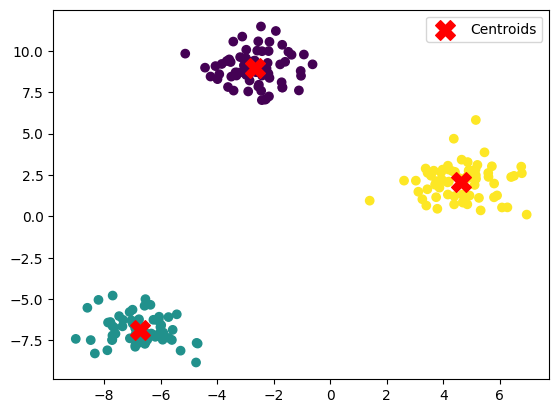

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate sample dataset
X, _ = make_blobs(
    n_samples=200,
    centers=3,
    random_state=42
)

# Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

kmeans.fit(X)

labels = kmeans.labels_

# Plot clusters
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis"
)

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.legend()
plt.show()

# Program 5

In [ ]:
pip install minisom

  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=MiniSom-2.3.6-py3-none-any.whl size=13083 sha256=e175645709f48c07bff0029aac3ef1690bcd76463b1e7c77e01fc4fad766a974
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


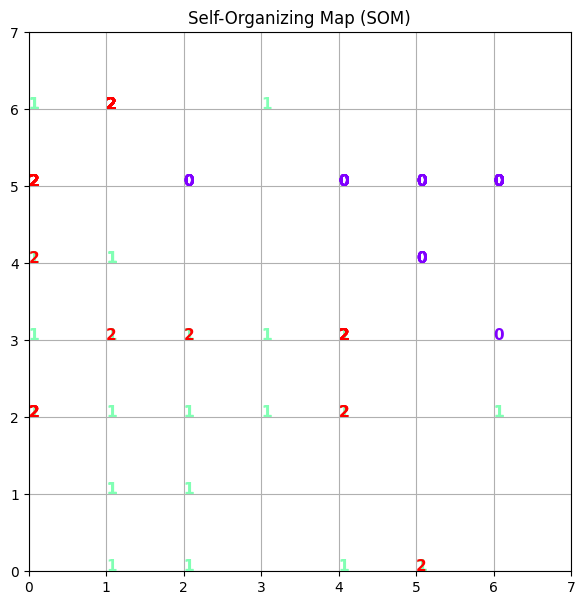

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

# Load Iris dataset
iris = load_iris()

# Normalize the data
X = MinMaxScaler().fit_transform(iris.data)

# Initialize SOM
som = MiniSom(
    x=7,
    y=7,
    input_len=4,
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X)

# Train SOM
som.train_random(X, 100)

# Visualize SOM
plt.figure(figsize=(7, 7))

for i, x in enumerate(X):
    w = som.winner(x)

    plt.text(
        w[0],
        w[1],
        str(iris.target[i]),
        color=plt.cm.rainbow(iris.target[i] / 2),
        fontdict={"weight": "bold", "size": 11}
    )

plt.xlim(0, 7)
plt.ylim(0, 7)
plt.grid()
plt.title("Self-Organizing Map (SOM)")
plt.show()

# Program 6

In [ ]:
import numpy as np

# Function to integrate
def f(x):
    return x**2

# Generate random samples
N = 10000
samples = np.random.rand(N)

# Evaluate function
values = f(samples)

# Monte Carlo estimate
estimate = np.mean(values)

print("Estimated Integral of x^2 from 0 to 1:", estimate)

Estimated Integral of x^2 from 0 to 1: 0.33599955315179014


# Program 7

In [2]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 3.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


SYNTHETIC DATASET
Dataset shape: (5000, 7)

First five rows:
      Age Smoker FamilyHistory Cholesterol BloodPressure HeartDisease  \
0     Old     No            No      Normal          High           No   
1     Old    Yes            No        High        Normal           No   
2  Middle    Yes            No        High        Normal           No   
3  Middle     No            No      Normal          High           No   
4   Young     No            No      Normal        Normal           No   

  ChestPain  
0        No  
1        No  
2        No  
3       Yes  
4        No  

Heart disease distribution:
HeartDisease
No     3653
Yes    1347
Name: count, dtype: int64

Heart disease proportions:
HeartDisease
No     0.7306
Yes    0.2694
Name: proportion, dtype: float64


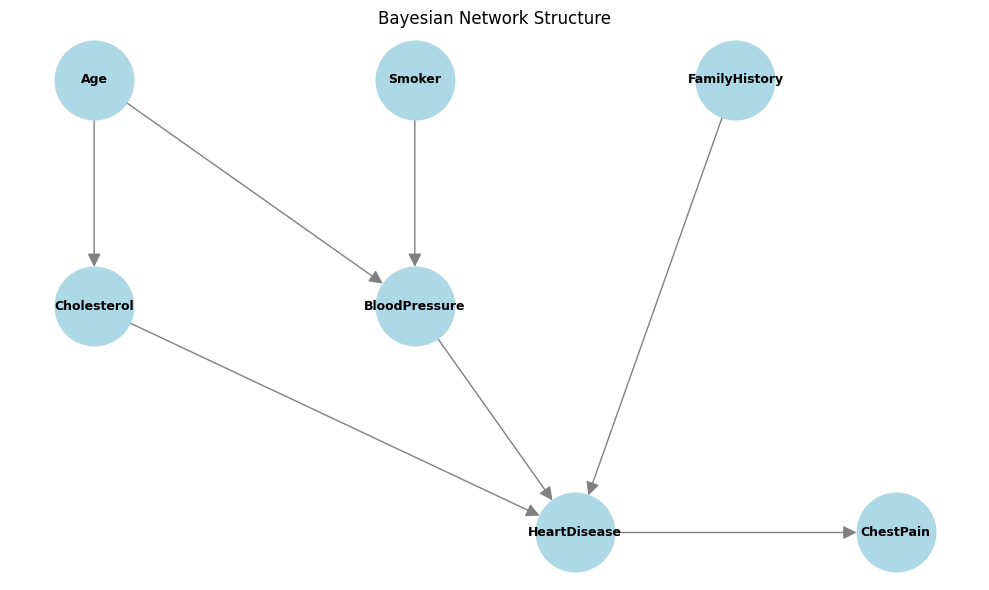

/tmp/ipykernel_3130/1890401556.py:197: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, data)



MODEL VALIDATION
Model valid: True

Conditional Probability Distributions (CPDs):

 +-------------+----------+
| Age(Middle) | 0.400067 |
+-------------+----------+
| Age(Old)    | 0.293679 |
+-------------+----------+
| Age(Young)  | 0.306254 |
+-------------+----------+

 +---------------------+-----+---------------------+
| Age                 | ... | Age(Young)          |
+---------------------+-----+---------------------+
| Cholesterol(High)   | ... | 0.14447099717575493 |
+---------------------+-----+---------------------+
| Cholesterol(Normal) | ... | 0.855529002824245   |
+---------------------+-----+---------------------+

 +-----------------------+-----+---------------------+
| Age                   | ... | Age(Young)          |
+-----------------------+-----+---------------------+
| Smoker                | ... | Smoker(Yes)         |
+-----------------------+-----+---------------------+
| BloodPressure(High)   | ... | 0.28954903364352186 |
+-----------------------+-----+---

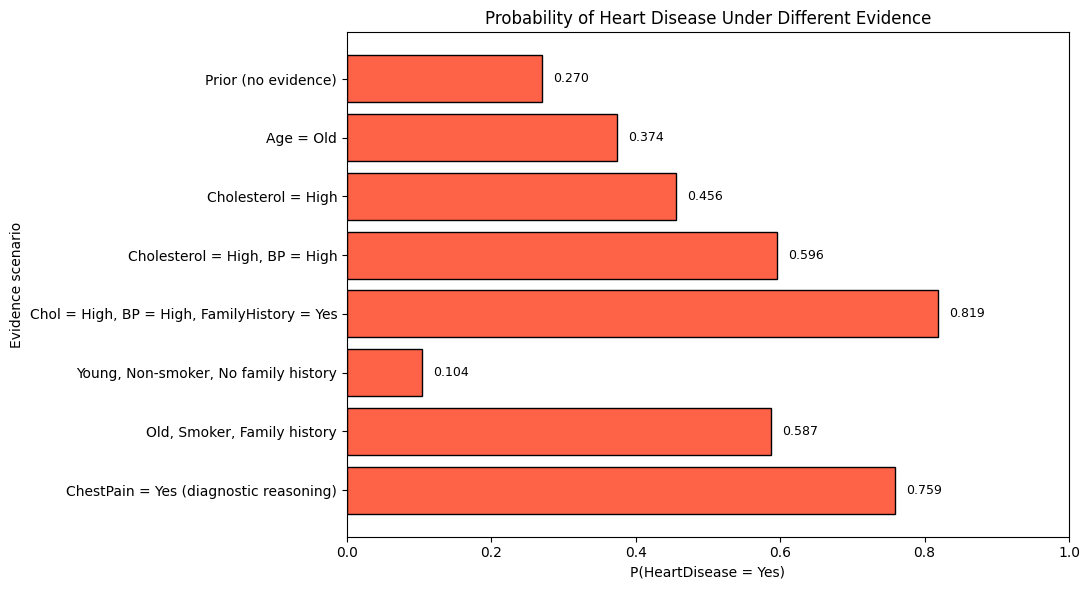


NEW PATIENT PREDICTION
New patient characteristics:
  Age: Middle
  Smoker: Yes
  FamilyHistory: No
  Cholesterol: High
  BloodPressure: High
New patient                                             P(HeartDisease = Yes) = 0.5202

Estimated probability: 52.02%
Model classification: Heart disease is more probable than not

Scenario comparison table:
                                   Scenario  Probability  Probability (%)
                        Prior (no evidence)     0.270099            27.01
                                  Age = Old     0.374093            37.41
                         Cholesterol = High     0.456267            45.63
              Cholesterol = High, BP = High     0.595786            59.58
Chol = High, BP = High, FamilyHistory = Yes     0.819001            81.90
       Young, Non-smoker, No family history     0.103726            10.37
                Old, Smoker, Family history     0.587149            58.71
     ChestPain = Yes (diagnostic reasoning)     0.759162 

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# --------------------------------------------------
# 1. IMPORT PGMPY COMPATIBLY
# --------------------------------------------------
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination


# --------------------------------------------------
# 2. GENERATE SYNTHETIC DATA
# --------------------------------------------------
rng = np.random.default_rng(42)
N = 5000


def pick(options, probs):
    """Randomly select a state using the specified probabilities."""
    return rng.choice(options, p=probs)


rows = []

for _ in range(N):

    # Demographic and lifestyle variables
    age = pick(
        ["Young", "Middle", "Old"],
        [0.30, 0.40, 0.30]
    )

    smoker = pick(
        ["Yes", "No"],
        [0.30, 0.70]
    )

    family = pick(
        ["Yes", "No"],
        [0.25, 0.75]
    )

    # Cholesterol depends on age
    p_high_chol = {
        "Young": 0.15,
        "Middle": 0.35,
        "Old": 0.55
    }[age]

    chol = pick(
        ["High", "Normal"],
        [p_high_chol, 1 - p_high_chol]
    )

    # Blood pressure depends on age and smoking
    p_high_bp = {
        "Young": 0.10,
        "Middle": 0.30,
        "Old": 0.50
    }[age]

    # FIX: Correct indentation inside the if block
    if smoker == "Yes":
        p_high_bp = min(p_high_bp + 0.20, 0.95)

    bp = pick(
        ["High", "Normal"],
        [p_high_bp, 1 - p_high_bp]
    )

    # Heart disease depends on family history,
    # cholesterol, and blood pressure
    p_hd = 0.05

    if family == "Yes":
        p_hd += 0.20

    if chol == "High":
        p_hd += 0.25

    if bp == "High":
        p_hd += 0.25

    hd = pick(
        ["Yes", "No"],
        [p_hd, 1 - p_hd]
    )

    # Chest pain depends on heart disease
    p_cp = 0.80 if hd == "Yes" else 0.10

    chest_pain = pick(
        ["Yes", "No"],
        [p_cp, 1 - p_cp]
    )

    rows.append([
        age,
        smoker,
        family,
        chol,
        bp,
        hd,
        chest_pain
    ])


data = pd.DataFrame(
    rows,
    columns=[
        "Age",
        "Smoker",
        "FamilyHistory",
        "Cholesterol",
        "BloodPressure",
        "HeartDisease",
        "ChestPain"
    ]
)

print("=" * 70)
print("SYNTHETIC DATASET")
print("=" * 70)

print("Dataset shape:", data.shape)
print("\nFirst five rows:")
print(data.head())

print("\nHeart disease distribution:")
print(data["HeartDisease"].value_counts())

print("\nHeart disease proportions:")
print(data["HeartDisease"].value_counts(normalize=True).round(4))


# --------------------------------------------------
# 3. DEFINE THE BAYESIAN NETWORK STRUCTURE
# --------------------------------------------------
model = BayesianNetwork([
    ("Age", "Cholesterol"),
    ("Age", "BloodPressure"),
    ("Smoker", "BloodPressure"),
    ("FamilyHistory", "HeartDisease"),
    ("Cholesterol", "HeartDisease"),
    ("BloodPressure", "HeartDisease"),
    ("HeartDisease", "ChestPain")
])


# --------------------------------------------------
# 4. VISUALIZE THE NETWORK STRUCTURE
# --------------------------------------------------
plt.figure(figsize=(10, 6))

G = nx.DiGraph()
G.add_edges_from(model.edges())

pos = {
    "Age": (0, 2),
    "Smoker": (2, 2),
    "FamilyHistory": (4, 2),
    "Cholesterol": (0, 1),
    "BloodPressure": (2, 1),
    "HeartDisease": (3, 0),
    "ChestPain": (5, 0)
}

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_color="lightblue",
    node_size=3200,
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=20,
    edge_color="gray"
)

plt.title("Bayesian Network Structure")
plt.axis("off")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 5. ESTIMATE CONDITIONAL PROBABILITY DISTRIBUTIONS
# --------------------------------------------------
estimator = BayesianEstimator(model, data)

cpds = [
    estimator.estimate_cpd(
        node,
        prior_type="BDeu",
        equivalent_sample_size=10
    )
    for node in model.nodes()
]

model.add_cpds(*cpds)


# --------------------------------------------------
# 6. VALIDATE THE MODEL
# --------------------------------------------------
print("\n" + "=" * 70)
print("MODEL VALIDATION")
print("=" * 70)

if not model.check_model():
    raise ValueError("The Bayesian network failed validation.")

print("Model valid:", model.check_model())

print("\nConditional Probability Distributions (CPDs):")

for cpd in model.get_cpds():
    print("\n", cpd)


# --------------------------------------------------
# 7. PERFORM PROBABILISTIC INFERENCE
# --------------------------------------------------
infer = VariableElimination(model)


def query_hd(evidence=None, label="No evidence"):
    """
    Calculate P(HeartDisease = Yes | evidence).
    Returns the posterior probability as a float.
    """
    result = infer.query(
        variables=["HeartDisease"],
        evidence=evidence,
        show_progress=False
    )

    states = result.state_names["HeartDisease"]
    yes_index = states.index("Yes")
    p_yes = float(result.values[yes_index])

    print(
        f"{label:<55} "
        f"P(HeartDisease = Yes) = {p_yes:.4f}"
    )

    return p_yes


# --------------------------------------------------
# 8. QUERY DIFFERENT SCENARIOS
# --------------------------------------------------
print("\n" + "=" * 90)
print("PROBABILITY OF HEART DISEASE UNDER DIFFERENT SCENARIOS")
print("=" * 90)

scenarios = [
    (
        None,
        "Prior (no evidence)"
    ),
    (
        {"Age": "Old"},
        "Age = Old"
    ),
    (
        {"Cholesterol": "High"},
        "Cholesterol = High"
    ),
    (
        {
            "Cholesterol": "High",
            "BloodPressure": "High"
        },
        "Cholesterol = High, BP = High"
    ),
    (
        {
            "Cholesterol": "High",
            "BloodPressure": "High",
            "FamilyHistory": "Yes"
        },
        "Chol = High, BP = High, FamilyHistory = Yes"
    ),
    (
        {
            "Age": "Young",
            "Smoker": "No",
            "FamilyHistory": "No"
        },
        "Young, Non-smoker, No family history"
    ),
    (
        {
            "Age": "Old",
            "Smoker": "Yes",
            "FamilyHistory": "Yes"
        },
        "Old, Smoker, Family history"
    ),
    (
        {"ChestPain": "Yes"},
        "ChestPain = Yes (diagnostic reasoning)"
    )
]

labels = []
probs = []

for evidence, label in scenarios:
    probability = query_hd(evidence, label)
    probs.append(probability)
    labels.append(label)


# --------------------------------------------------
# 9. VISUALIZE SCENARIO PROBABILITIES
# --------------------------------------------------
results_df = pd.DataFrame({
    "Scenario": labels,
    "Probability": probs
})

plt.figure(figsize=(11, 6))

bars = plt.barh(
    results_df["Scenario"],
    results_df["Probability"],
    color="tomato",
    edgecolor="black"
)

plt.xlabel("P(HeartDisease = Yes)")
plt.ylabel("Evidence scenario")
plt.title("Probability of Heart Disease Under Different Evidence")
plt.xlim(0, 1)
plt.gca().invert_yaxis()

# Display probability values beside the bars
for bar, probability in zip(bars, probs):
    plt.text(
        min(probability + 0.015, 0.95),
        bar.get_y() + bar.get_height() / 2,
        f"{probability:.3f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 10. PREDICT FOR A NEW PATIENT
# --------------------------------------------------
new_patient = {
    "Age": "Middle",
    "Smoker": "Yes",
    "FamilyHistory": "No",
    "Cholesterol": "High",
    "BloodPressure": "High"
}

print("\n" + "=" * 70)
print("NEW PATIENT PREDICTION")
print("=" * 70)

print("New patient characteristics:")

for feature, value in new_patient.items():
    print(f"  {feature}: {value}")

p = query_hd(new_patient, "New patient")

print(f"\nEstimated probability: {p:.2%}")

if p >= 0.5:
    prediction = "Heart disease is more probable than not"
else:
    prediction = "Heart disease is less probable than not"

print("Model classification:", prediction)


# --------------------------------------------------
# 11. OPTIONAL: DISPLAY RESULTS AS A TABLE
# --------------------------------------------------
print("\nScenario comparison table:")

results_df["Probability (%)"] = (
    results_df["Probability"] * 100
).round(2)

print(
    results_df[
        ["Scenario", "Probability", "Probability (%)"]
    ].to_string(index=False)
)


# Program 8

STEP 1: Dataset created (5000, 7)
      Age Smoker FamilyHistory Cholesterol BloodPressure HeartDisease  \
0     Old     No            No      Normal          High           No   
1     Old    Yes            No        High        Normal           No   
2  Middle    Yes            No        High        Normal           No   
3  Middle     No            No      Normal          High           No   
4   Young     No            No      Normal        Normal           No   

  ChestPain  
0        No  
1        No  
2        No  
3       Yes  
4        No   



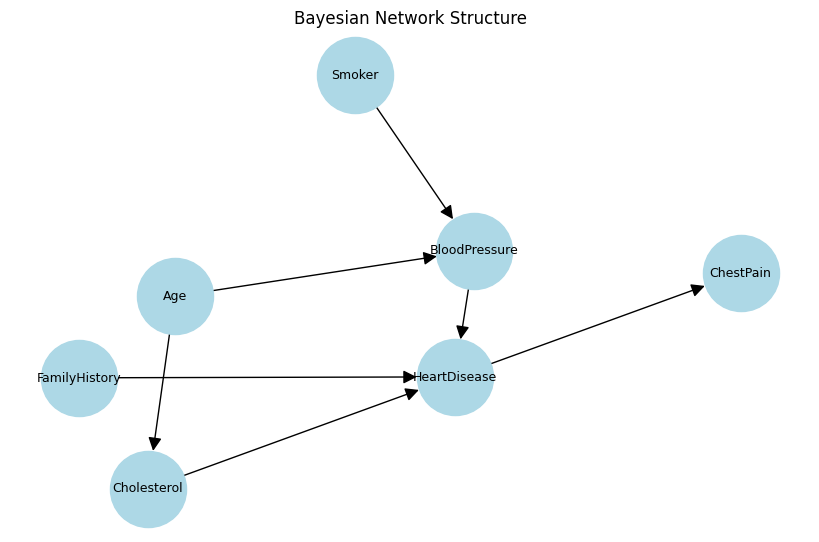

STEP 2: Network structure defined

STEP 3: CPDs learned. Model valid: True 

SEQUENCE A: High-risk patient (evidence accumulates)
Step Evidence added               P(HD=Yes)  Change    Inference
-----------------------------------------------------------------------------------------------
0    None (prior)                 0.2701     --        Baseline risk in the population.
1    Age = Old                    0.3741     +0.1040   Age=Old INCREASES the risk of heart disease.
2    Smoker = Yes                 0.4110     +0.0369   Smoker=Yes INCREASES the risk of heart disease.
3    FamilyHistory = Yes          0.5871     +0.1761   FamilyHistory=Yes INCREASES the risk of heart disease.
4    Cholesterol = High           0.7322     +0.1451   Cholesterol=High INCREASES the risk of heart disease.
5    BloodPressure = High         0.8190     +0.0868   BloodPressure=High INCREASES the risk of heart disease.
6    ChestPain = Yes              0.9747     +0.1557   ChestPain=Yes INCREASES the risk 

/tmp/ipykernel_3130/4011770663.py:90: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, data)


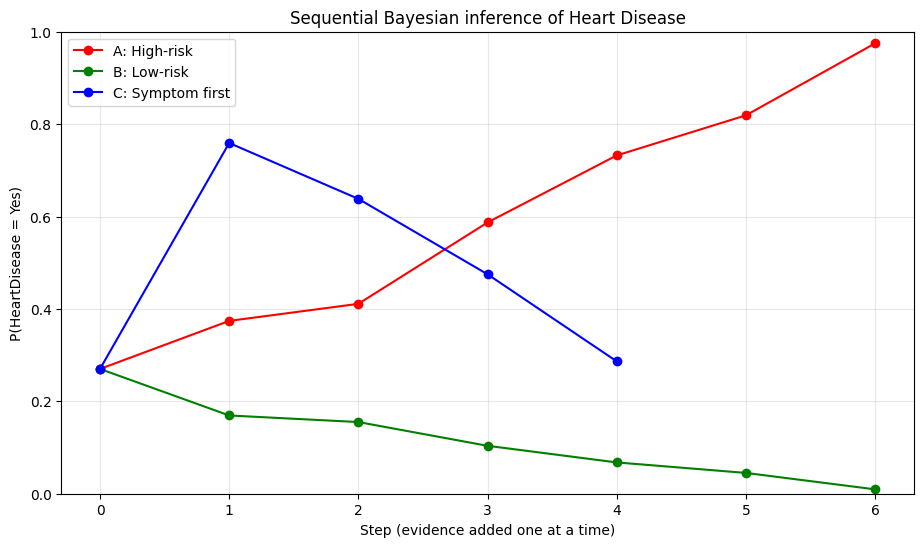

CONCLUSIONS
-----------------------------------------------------------------------------------------------
1. With no evidence the model gives the baseline (prior) probability of heart disease.
2. Each risk factor (old age, smoking, family history, high cholesterol, high BP)
   raises the probability when added, and protective evidence lowers it.
3. Age and Smoker act indirectly: they change Cholesterol/BP, which then affect heart disease.
4. Observing ChestPain=Yes raises the belief in heart disease (effect -> cause reasoning).
5. Once Cholesterol, BP and FamilyHistory are known, the remaining evidence matters less,
   because the network's structure makes them the direct parents of HeartDisease.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx


try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork  # newer pgmpy
except ImportError:
    from pgmpy.models import BayesianNetwork                              # older pgmpy


from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination




rng = np.random.default_rng(42)
N = 5000


def pick(options, probs):
    return rng.choice(options, p=probs)


rows = []
for _ in range(N):
    age    = pick(["Young", "Middle", "Old"], [0.30, 0.40, 0.30])
    smoker = pick(["Yes", "No"], [0.30, 0.70])
    family = pick(["Yes", "No"], [0.25, 0.75])


    p_high_chol = {"Young": 0.15, "Middle": 0.35, "Old": 0.55}[age]
    chol = pick(["High", "Normal"], [p_high_chol, 1 - p_high_chol])


    p_high_bp = {"Young": 0.10, "Middle": 0.30, "Old": 0.50}[age]
    if smoker == "Yes":
        p_high_bp = min(p_high_bp + 0.20, 0.95)
    bp = pick(["High", "Normal"], [p_high_bp, 1 - p_high_bp])


    p_hd = 0.05
    if family == "Yes": p_hd += 0.20
    if chol == "High":  p_hd += 0.25
    if bp == "High":    p_hd += 0.25
    hd = pick(["Yes", "No"], [p_hd, 1 - p_hd])


    p_cp = 0.80 if hd == "Yes" else 0.10
    chest_pain = pick(["Yes", "No"], [p_cp, 1 - p_cp])


    rows.append([age, smoker, family, chol, bp, hd, chest_pain])


data = pd.DataFrame(rows, columns=[
    "Age", "Smoker", "FamilyHistory", "Cholesterol",
    "BloodPressure", "HeartDisease", "ChestPain"
])
print("STEP 1: Dataset created", data.shape)
print(data.head(), "\n")




model = BayesianNetwork([
    ("Age", "Cholesterol"),
    ("Age", "BloodPressure"),
    ("Smoker", "BloodPressure"),
    ("FamilyHistory", "HeartDisease"),
    ("Cholesterol", "HeartDisease"),
    ("BloodPressure", "HeartDisease"),
    ("HeartDisease", "ChestPain"),
])


plt.figure(figsize=(8, 5))
G = nx.DiGraph(list(model.edges()))
nx.draw(G, with_labels=True, node_color="lightblue", node_size=3000,
        font_size=9, arrowsize=20, pos=nx.spring_layout(G, seed=3))
plt.title("Bayesian Network Structure")
plt.show()
print("STEP 2: Network structure defined\n")




estimator = BayesianEstimator(model, data)
cpds = [estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
        for node in model.nodes()]
model.add_cpds(*cpds)
print("STEP 3: CPDs learned. Model valid:", model.check_model(), "\n")




infer = VariableElimination(model)


def prob(var, state, evidence=None):
    res = infer.query(variables=[var], evidence=evidence or None, show_progress=False)
    return float(res.values[res.state_names[var].index(state)])


def sequential_inference(steps, title):
    print("=" * 95)
    print(title)
    print("=" * 95)
    evidence = {}
    prev = prob("HeartDisease", "Yes")
    records = [("Prior (no evidence)", prev, 0.0, "Baseline risk in the population.")]
    print(f"{'Step':<4} {'Evidence added':<28} {'P(HD=Yes)':<10} {'Change':<9} Inference")
    print("-" * 95)
    print(f"{0:<4} {'None (prior)':<28} {prev:<10.4f} {'--':<9} Baseline risk in the population.")


    for i, (var, val) in enumerate(steps, 1):
        evidence[var] = val
        cur = prob("HeartDisease", "Yes", evidence)
        delta = cur - prev
        if delta > 0.02:
            msg = f"{var}={val} INCREASES the risk of heart disease."
        elif delta < -0.02:
            msg = f"{var}={val} DECREASES the risk of heart disease."
        else:
            msg = f"{var}={val} has little direct effect on the risk."
        print(f"{i:<4} {var + ' = ' + val:<28} {cur:<10.4f} {delta:<+9.4f} {msg}")
        records.append((f"+ {var}={val}", cur, delta, msg))
        prev = cur


    final = prev
    level = "HIGH" if final >= 0.6 else "MODERATE" if final >= 0.3 else "LOW"
    print("-" * 95)
    print(f"FINAL: P(HeartDisease=Yes | all evidence) = {final:.4f}  ->  {level} likelihood\n")
    return records


# Sequence A: risk factors accumulate, then symptom appears
seqA = [("Age", "Old"), ("Smoker", "Yes"), ("FamilyHistory", "Yes"),
        ("Cholesterol", "High"), ("BloodPressure", "High"), ("ChestPain", "Yes")]
recA = sequential_inference(seqA, "SEQUENCE A: High-risk patient (evidence accumulates)")


# Sequence B: protective factors accumulate, then no symptom
seqB = [("Age", "Young"), ("Smoker", "No"), ("FamilyHistory", "No"),
        ("Cholesterol", "Normal"), ("BloodPressure", "Normal"), ("ChestPain", "No")]
recB = sequential_inference(seqB, "SEQUENCE B: Low-risk patient (evidence accumulates)")


# Sequence C: symptom first (diagnostic reasoning), then explain it
seqC = [("ChestPain", "Yes"), ("Cholesterol", "Normal"), ("BloodPressure", "Normal"),
        ("FamilyHistory", "No")]
recC = sequential_inference(seqC, "SEQUENCE C: Symptom first (diagnostic reasoning)")




print("=" * 95)
print("DIAGNOSTIC (BACKWARD) INFERENCE: updating belief about causes")
print("=" * 95)
for ev_name, ev in [("No evidence", None),
                    ("ChestPain = Yes", {"ChestPain": "Yes"}),
                    ("HeartDisease = Yes", {"HeartDisease": "Yes"})]:
    print(f"{ev_name:<22} P(Chol=High)={prob('Cholesterol','High',ev):.3f}  "
          f"P(BP=High)={prob('BloodPressure','High',ev):.3f}  "
          f"P(Family=Yes)={prob('FamilyHistory','Yes',ev):.3f}  "
          f"P(Smoker=Yes)={prob('Smoker','Yes',ev):.3f}")
print()




plt.figure(figsize=(11, 6))
for recs, name, color in [(recA, "A: High-risk", "red"),
                          (recB, "B: Low-risk", "green"),
                          (recC, "C: Symptom first", "blue")]:
    plt.plot(range(len(recs)), [r[1] for r in recs], marker="o", label=name, color=color)


plt.xlabel("Step (evidence added one at a time)")
plt.ylabel("P(HeartDisease = Yes)")
plt.title("Sequential Bayesian inference of Heart Disease")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()




print("CONCLUSIONS")
print("-" * 95)
print("1. With no evidence the model gives the baseline (prior) probability of heart disease.")
print("2. Each risk factor (old age, smoking, family history, high cholesterol, high BP)")
print("   raises the probability when added, and protective evidence lowers it.")
print("3. Age and Smoker act indirectly: they change Cholesterol/BP, which then affect heart disease.")
print("4. Observing ChestPain=Yes raises the belief in heart disease (effect -> cause reasoning).")
print("5. Once Cholesterol, BP and FamilyHistory are known, the remaining evidence matters less,")
print("   because the network's structure makes them the direct parents of HeartDisease.")